In [3]:
!pip -q install requests seaborn scikit-learn tensorflow

In [2]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
url = (
    "https://api.worldbank.org/v2/country/IND/"
    "indicator/SL.UEM.TOTL.ZS"
)

params = {
    "date": "2000:2023",
    "format": "json",
    "per_page": 100
}

response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()[1]

df = pd.DataFrame([
    {
        "country": row["country"]["value"],
        "year": int(row["date"]),
        "unemployment_rate": row["value"]
    }
    for row in data
])

print(df.head())
print("Dataset shape:", df.shape)

  country  year  unemployment_rate
0   India  2023              4.172
1   India  2022              4.822
2   India  2021              6.380
3   India  2020              7.859
4   India  2019              6.510
Dataset shape: (24, 3)


In [6]:
print("First five rows:")
display(df.head())

print("Number of rows and columns:")
print(df.shape)

print("Column names:")
print(df.columns.tolist())

print("Missing values:")
print(df.isnull().sum())

print("Statistical summary:")
display(df.describe())

First five rows:


,country,year,unemployment_rate
0,India,2023,4.172
1,India,2022,4.822
2,India,2021,6.380
3,India,2020,7.859
4,India,2019,6.510


Number of rows and columns:
(24, 3)
Column names:
['country', 'year', 'unemployment_rate']
Missing values:
country              0
year                 0
unemployment_rate    0
dtype: int64
Statistical summary:


,year,unemployment_rate
count,24.000000,24.000000
mean,2011.500000,7.271792
std,7.071068,0.924532
min,2000.000000,4.172000
25%,2005.750000,7.559750
50%,2011.500000,7.618500
75%,2017.250000,7.638250
max,2023.000000,7.859000


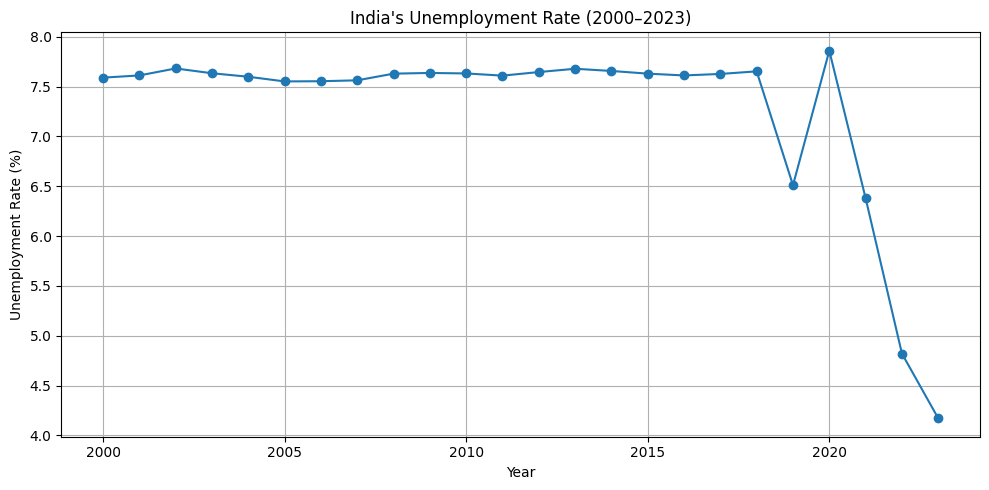

In [7]:
df_plot = df.dropna(subset=["unemployment_rate"])

plt.figure(figsize=(10, 5))

plt.plot(
    df_plot["year"],
    df_plot["unemployment_rate"],
    marker="o"
)

plt.title("India's Unemployment Rate (2000–2023)")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
import requests
import pandas as pd
import time

country_code = "IND"

indicators = {
    "unemployment_rate": "SL.UEM.TOTL.ZS",
    "gdp_growth": "NY.GDP.MKTP.KD.ZG",
    "gdp_per_capita": "NY.GDP.PCAP.CD",
    "inflation": "FP.CPI.TOTL.ZG",
    "labor_force_participation": "SL.TLF.CACT.ZS",
    "population": "SP.POP.TOTL",
    "urban_population_percent": "SP.URB.TOTL.IN.ZS",
    "internet_users_percent": "IT.NET.USER.ZS",
    "foreign_direct_investment": "BX.KLT.DINV.CD.WD",
    "trade_percent_gdp": "NE.TRD.GNFS.ZS",
    "life_expectancy": "SP.DYN.LE00.IN",
    "female_labor_participation": "SL.TLF.CACT.FE.ZS",
    "agriculture_value_added": "NV.AGR.TOTL.ZS",
    "industry_value_added": "NV.IND.TOTL.ZS",
    "services_value_added": "NV.SRV.TOTL.ZS",
    "gross_capital_formation": "NE.GDI.TOTL.ZS"
}

base_url = "https://api.worldbank.org/v2/country"

data_frames = []

for feature, indicator_code in indicators.items():
    url = (
        f"{base_url}/{country_code}/indicator/"
        f"{indicator_code}"
    )

    params = {
        "date": "2000:2023",
        "format": "json",
        "per_page": 100
    }

    max_retries = 3
    backoff_factor = 2
    response_received = False

    for attempt in range(max_retries):
        try:
            response = requests.get(url, params=params, timeout=30)
            response.raise_for_status()
            result = response.json()
            response_received = True
            break
        except (requests.exceptions.RequestException, requests.exceptions.Timeout) as e:
            wait_time = backoff_factor ** attempt
            print(f"Attempt {attempt + 1} failed for {feature} due to error: {e}. Retrying in {wait_time}s...")
            time.sleep(wait_time)

    if not response_received:
        print(f"Skipping {feature} as it consistently failed after {max_retries} attempts.")
        continue

    if len(result) < 2 or result[1] is None:
        print("No data returned for:", feature)
        continue

    temp = pd.DataFrame([
        {
            "year": int(row["date"]),
            feature: row["value"]
        }
        for row in result[1]
    ])

    data_frames.append(temp)
    print("Downloaded:", feature)
    time.sleep(0.5)

if data_frames:
    df = data_frames[0]
    for temp in data_frames[1:]:
        df = df.merge(temp, on="year", how="outer")

    df = df.sort_values("year").reset_index(drop=True)
    print("\nDataset downloaded successfully!")
    print("Dataset shape:", df.shape)
    display(df.head())
else:
    print("No data frames were successfully downloaded.")

Downloaded: unemployment_rate
Downloaded: gdp_growth
Attempt 1 failed for gdp_per_capita due to error: HTTPSConnectionPool(host='api.worldbank.org', port=443): Read timed out. (read timeout=30). Retrying in 1s...
Downloaded: gdp_per_capita
Downloaded: inflation
Attempt 1 failed for labor_force_participation due to error: HTTPSConnectionPool(host='api.worldbank.org', port=443): Read timed out. (read timeout=30). Retrying in 1s...
Downloaded: labor_force_participation
Downloaded: population
Downloaded: urban_population_percent
Downloaded: internet_users_percent
Downloaded: foreign_direct_investment
Downloaded: trade_percent_gdp
Downloaded: life_expectancy
Attempt 1 failed for female_labor_participation due to error: HTTPSConnectionPool(host='api.worldbank.org', port=443): Read timed out. (read timeout=30). Retrying in 1s...
Downloaded: female_labor_participation
Downloaded: agriculture_value_added
Downloaded: industry_value_added
Attempt 1 failed for services_value_added due to error: HT

,year,unemployment_rate,gdp_growth,gdp_per_capita,inflation,labor_force_participation,population,urban_population_percent,internet_users_percent,foreign_direct_investment,trade_percent_gdp,life_expectancy,female_labor_participation,agriculture_value_added,industry_value_added,services_value_added,gross_capital_formation
0,2000,7.589,3.840991,442.750219,4.009436,60.079,1057922733,27.647041,0.527532,3.584217e+09,26.900923,62.749,34.397,21.611062,27.325828,42.732927,25.677317
1,2001,7.611,4.823966,450.357901,3.779293,59.923,1077898575,27.902865,0.660146,5.128094e+09,25.993255,63.158,34.483,21.618885,26.487777,43.808961,29.907889
2,2002,7.681,3.803975,469.149929,4.297152,59.765,1097600380,28.175688,1.537876,5.208967e+09,29.508663,63.649,34.570,19.534543,27.660654,44.728828,30.251300
3,2003,7.633,7.860381,544.143134,3.805859,59.606,1116803006,28.466029,1.686490,3.681985e+09,30.592436,64.086,34.660,19.591998,27.474107,44.704646,30.839700
4,2004,7.598,7.922937,624.258827,3.767252,59.445,1135991513,28.772607,1.976136,5.429251e+09,37.503814,64.484,34.753,17.814691,29.219106,44.114859,35.096492


In [10]:
print("Dataset dimensions:", df.shape)

print("\nAll column names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset dimensions: (24, 17)

All column names:
['year', 'unemployment_rate', 'gdp_growth', 'gdp_per_capita', 'inflation', 'labor_force_participation', 'population', 'urban_population_percent', 'internet_users_percent', 'foreign_direct_investment', 'trade_percent_gdp', 'life_expectancy', 'female_labor_participation', 'agriculture_value_added', 'industry_value_added', 'services_value_added', 'gross_capital_formation']

Missing values in each column:
year                          0
unemployment_rate             0
gdp_growth                    0
gdp_per_capita                0
inflation                     0
labor_force_participation     0
population                    0
urban_population_percent      0
internet_users_percent        0
foreign_direct_investment     0
trade_percent_gdp             0
life_expectancy               0
female_labor_participation    0
agriculture_value_added       0
industry_value_added          0
services_value_added          0
gross_capital_formation       0
dty

,year,unemployment_rate,gdp_growth,gdp_per_capita,inflation,labor_force_participation,population,urban_population_percent,internet_users_percent,foreign_direct_investment,trade_percent_gdp,life_expectancy,female_labor_participation,agriculture_value_added,industry_value_added,services_value_added,gross_capital_formation
count,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,2.400000e+01,24.000000,24.000000,2.400000e+01,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
mean,2011.500000,7.271792,6.164255,1352.982687,6.138533,55.444042,1.262709e+09,31.339243,16.146768,2.972690e+10,43.061003,67.453458,29.869583,17.653438,28.014682,46.167077,34.146235
std,7.071068,0.924532,3.093551,632.502728,2.531401,2.976707,1.184499e+08,2.338988,18.186847,1.752012e+10,8.575878,2.762180,3.416991,1.531866,2.074328,1.861568,4.256089
min,2000.000000,4.172000,-5.777725,442.750219,3.328173,51.547000,1.057923e+09,27.647041,0.527532,3.584217e+09,25.993255,62.749000,25.998000,16.031631,24.591475,42.732927,25.677317
25%,2005.750000,7.559750,5.136979,778.873285,3.991784,52.986250,1.168328e+09,29.346877,2.701150,1.683919e+10,39.368579,65.264500,26.600750,16.754206,26.482464,44.639217,30.692600
50%,2011.500000,7.618500,7.310226,1431.082985,5.390275,54.414000,1.269950e+09,31.432272,10.585000,3.136484e+10,44.520029,67.452500,28.886500,17.087466,27.565254,46.143015,34.145502
75%,2017.250000,7.638250,7.923060,1917.808058,7.111592,58.581000,1.363408e+09,33.261208,18.670326,4.355708e+10,49.005441,69.798750,33.723500,17.913684,29.690743,47.757988,38.366167
max,2023.000000,7.859000,9.689592,2434.448263,11.989390,60.079000,1.438070e+09,35.067692,60.252300,6.436236e+10,55.793722,72.003000,34.852000,21.618885,31.136719,50.084958,41.950798


In [11]:
# Check missing values again
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Replace infinite values with missing values
import numpy as np

df = df.replace([np.inf, -np.inf], np.nan)

# Fill missing values in numeric columns using column medians
for column in df.columns:
    if column != "year":
        df[column] = df[column].fillna(df[column].median())

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nFinal dataset shape:", df.shape)
display(df.head())

Missing values before cleaning:
year                          0
unemployment_rate             0
gdp_growth                    0
gdp_per_capita                0
inflation                     0
labor_force_participation     0
population                    0
urban_population_percent      0
internet_users_percent        0
foreign_direct_investment     0
trade_percent_gdp             0
life_expectancy               0
female_labor_participation    0
agriculture_value_added       0
industry_value_added          0
services_value_added          0
gross_capital_formation       0
dtype: int64

Total missing values: 0

Missing values after cleaning:
year                          0
unemployment_rate             0
gdp_growth                    0
gdp_per_capita                0
inflation                     0
labor_force_participation     0
population                    0
urban_population_percent      0
internet_users_percent        0
foreign_direct_investment     0
trade_percent_gdp             0
li

,year,unemployment_rate,gdp_growth,gdp_per_capita,inflation,labor_force_participation,population,urban_population_percent,internet_users_percent,foreign_direct_investment,trade_percent_gdp,life_expectancy,female_labor_participation,agriculture_value_added,industry_value_added,services_value_added,gross_capital_formation
0,2000,7.589,3.840991,442.750219,4.009436,60.079,1057922733,27.647041,0.527532,3.584217e+09,26.900923,62.749,34.397,21.611062,27.325828,42.732927,25.677317
1,2001,7.611,4.823966,450.357901,3.779293,59.923,1077898575,27.902865,0.660146,5.128094e+09,25.993255,63.158,34.483,21.618885,26.487777,43.808961,29.907889
2,2002,7.681,3.803975,469.149929,4.297152,59.765,1097600380,28.175688,1.537876,5.208967e+09,29.508663,63.649,34.570,19.534543,27.660654,44.728828,30.251300
3,2003,7.633,7.860381,544.143134,3.805859,59.606,1116803006,28.466029,1.686490,3.681985e+09,30.592436,64.086,34.660,19.591998,27.474107,44.704646,30.839700
4,2004,7.598,7.922937,624.258827,3.767252,59.445,1135991513,28.772607,1.976136,5.429251e+09,37.503814,64.484,34.753,17.814691,29.219106,44.114859,35.096492


In [12]:
print("Missing values:", df.isnull().sum().sum())

print("\nCheck 2004 row:")
display(df[df["year"] == 2004].T)

print("\nData types:")
print(df.dtypes)

print("\nDuplicate rows:", df.duplicated().sum())

Missing values: 0

Check 2004 row:


,4
year,2.004000e+03
unemployment_rate,7.598000e+00
gdp_growth,7.922937e+00
gdp_per_capita,6.242588e+02
inflation,3.767252e+00
labor_force_participation,5.944500e+01
population,1.135992e+09
urban_population_percent,2.877261e+01
internet_users_percent,1.976136e+00
foreign_direct_investment,5.429251e+09



Data types:
year                            int64
unemployment_rate             float64
gdp_growth                    float64
gdp_per_capita                float64
inflation                     float64
labor_force_participation     float64
population                      int64
urban_population_percent      float64
internet_users_percent        float64
foreign_direct_investment     float64
trade_percent_gdp             float64
life_expectancy               float64
female_labor_participation    float64
agriculture_value_added       float64
industry_value_added          float64
services_value_added          float64
gross_capital_formation       float64
dtype: object

Duplicate rows: 0


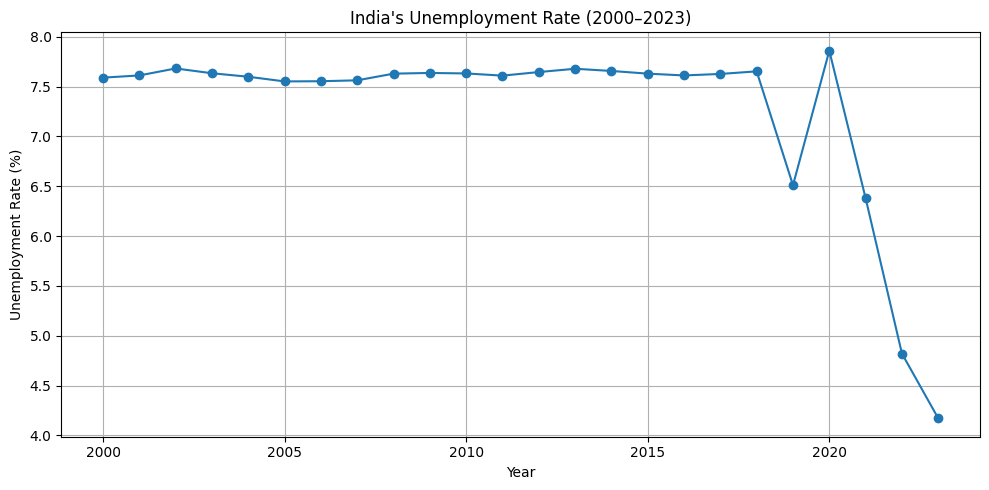

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    df["year"],
    df["unemployment_rate"],
    marker="o"
)

plt.title("India's Unemployment Rate (2000–2023)")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

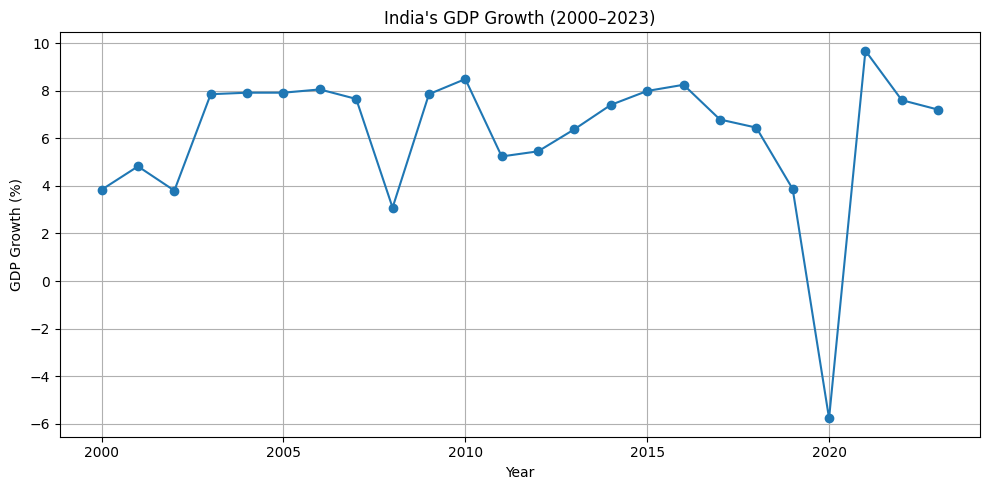

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(
    df["year"],
    df["gdp_growth"],
    marker="o"
)

plt.title("India's GDP Growth (2000–2023)")
plt.xlabel("Year")
plt.ylabel("GDP Growth (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

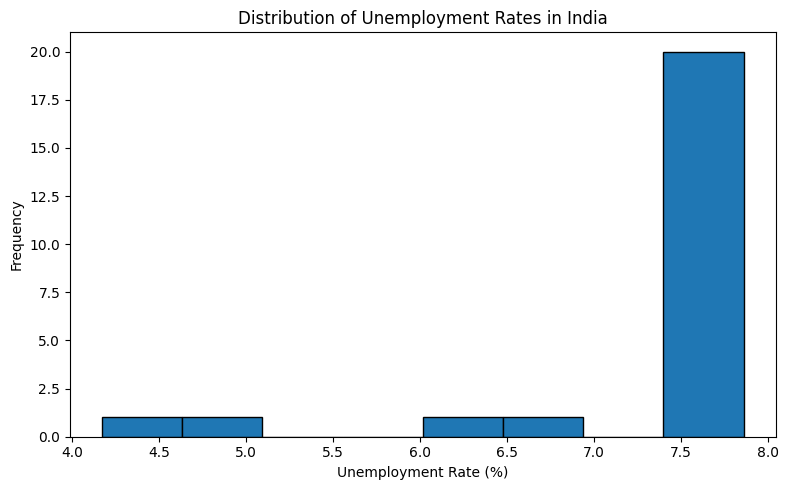

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["unemployment_rate"],
    bins=8,
    edgecolor="black"
)

plt.title("Distribution of Unemployment Rates in India")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

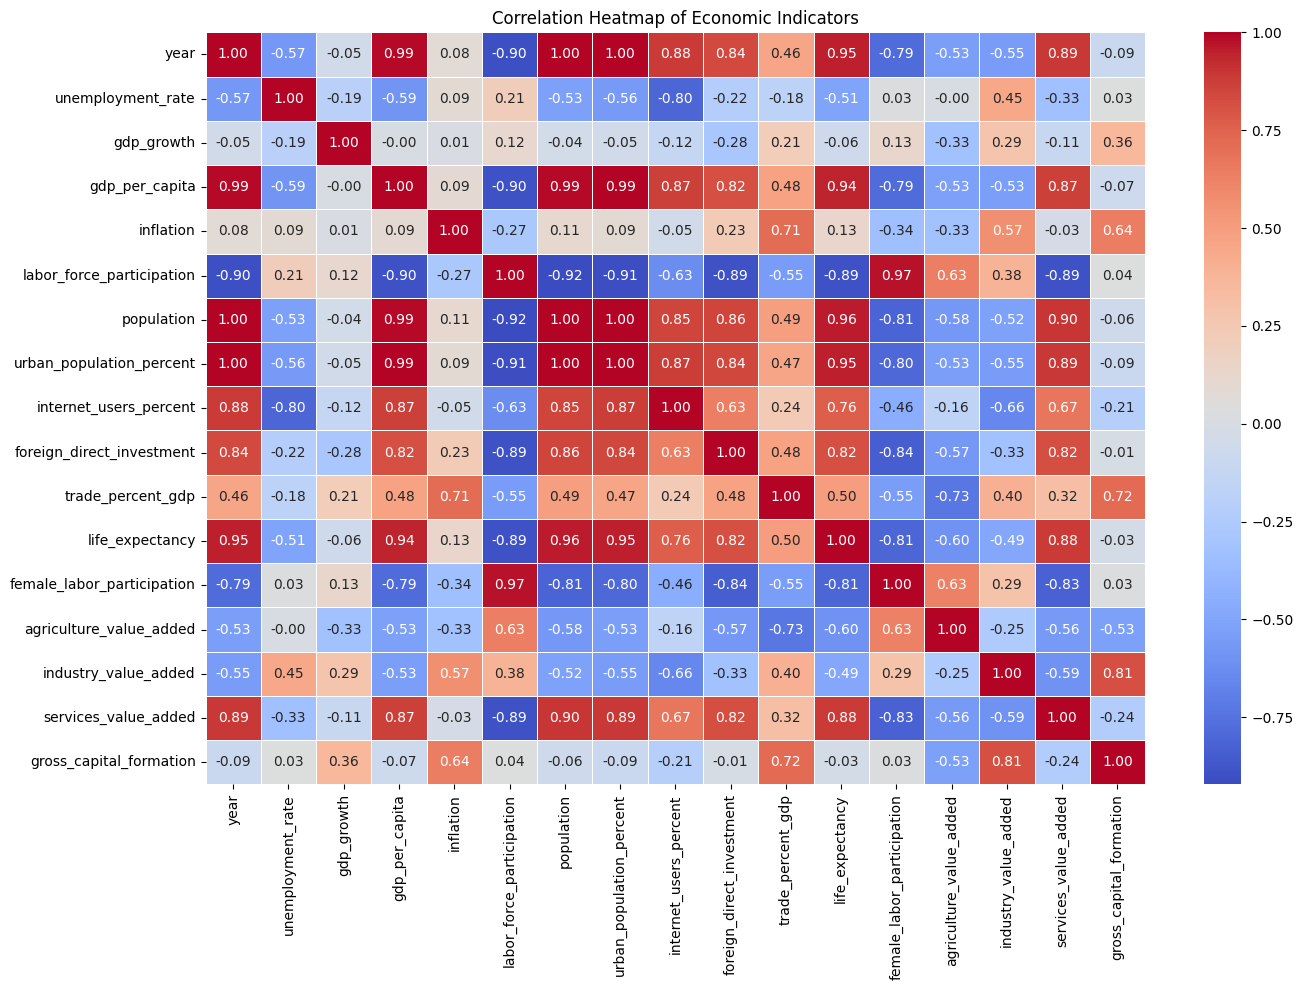

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Economic Indicators")
plt.tight_layout()
plt.show()

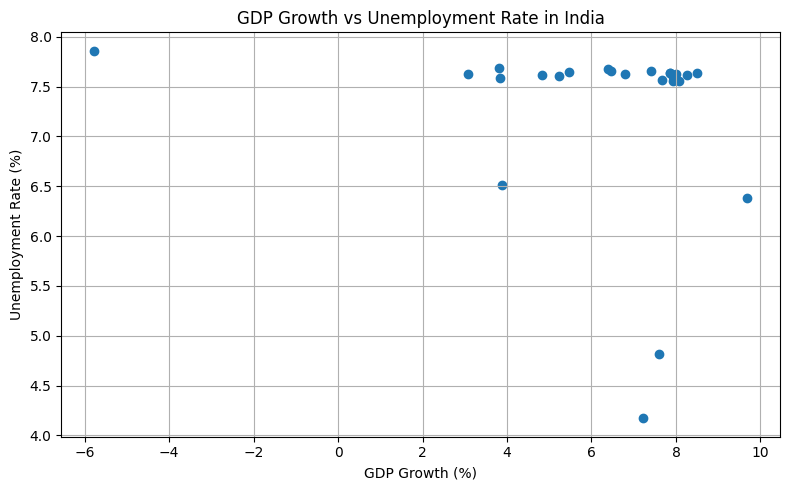

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["gdp_growth"],
    df["unemployment_rate"]
)

plt.title("GDP Growth vs Unemployment Rate in India")
plt.xlabel("GDP Growth (%)")
plt.ylabel("Unemployment Rate (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
# Sort data chronologically
df = df.sort_values("year").reset_index(drop=True)

# Input features: all columns except year and target
feature_columns = [
    column for column in df.columns
    if column not in ["year", "unemployment_rate"]
]

X = df[feature_columns].copy()
y = df["unemployment_rate"].copy()

print("Number of input features:", len(feature_columns))
print("Feature columns:")
print(feature_columns)

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Number of input features: 15
Feature columns:
['gdp_growth', 'gdp_per_capita', 'inflation', 'labor_force_participation', 'population', 'urban_population_percent', 'internet_users_percent', 'foreign_direct_investment', 'trade_percent_gdp', 'life_expectancy', 'female_labor_participation', 'agriculture_value_added', 'industry_value_added', 'services_value_added', 'gross_capital_formation']

Input shape: (24, 15)
Target shape: (24,)


In [20]:
train_mask = df["year"] <= 2017
val_mask = df["year"].between(2018, 2020)
test_mask = df["year"] >= 2021

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[val_mask]
y_val = y.loc[val_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))

Training rows: 18
Validation rows: 3
Testing rows: 3


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training data standardized successfully!")
print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training data standardized successfully!
Training shape: (18, 15)
Validation shape: (3, 15)
Testing shape: (3, 15)


In [22]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

# Make results more reproducible
tf.keras.utils.set_random_seed(42)

# Build the MLP regression model
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="linear")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=200,
    batch_size=4,
    callbacks=[early_stopping],
    verbose=1
)

print("\nTraining completed!")
print("Epochs completed:", len(history.history["loss"]))

Epoch 1/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - loss: 57.8357 - mae: 7.5833 - val_loss: 59.9866 - val_mae: 7.7290
Epoch 2/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 55.0836 - mae: 7.3884 - val_loss: 56.3546 - val_mae: 7.4913
Epoch 3/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 51.2479 - mae: 7.1228 - val_loss: 52.7047 - val_mae: 7.2441
Epoch 4/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 48.8275 - mae: 6.9524 - val_loss: 49.6457 - val_mae: 7.0292
Epoch 5/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 46.4987 - mae: 6.7591 - val_loss: 46.9106 - val_mae: 6.8309
Epoch 6/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 43.2359 - mae: 6.4948 - val_loss: 44.2637 - val_mae: 6.6317
Epoch 7/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 43.6609 - mae: 6.5353 - val_loss: 41.6962 - val_mae: 6.4300
Epoch 8/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 39.1218 - mae: 6.1504 - val_loss: 39.0638 - val_mae: 6.2147
Epoch 9/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - los

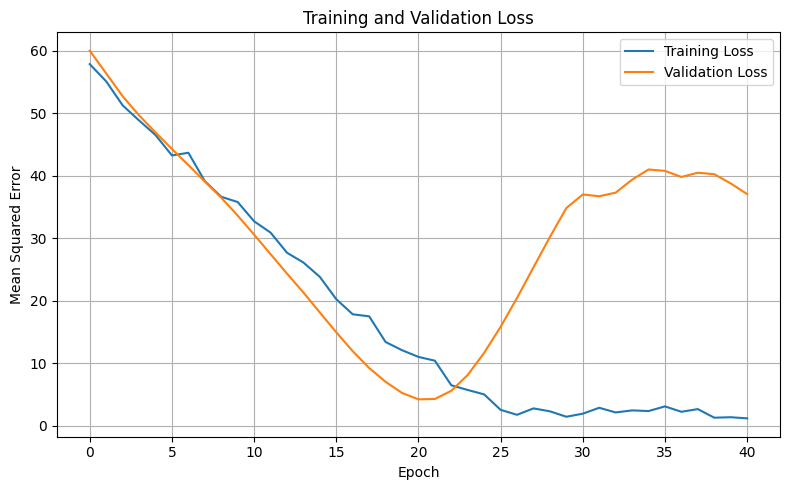

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Predict unemployment rates for test data
y_pred = model.predict(X_test_scaled).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("TEST RESULTS")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R-squared:", round(r2, 4))

# Compare actual and predicted values
results = pd.DataFrame({
    "Year": df.loc[X_test.index, "year"].values,
    "Actual Unemployment Rate": y_test.values,
    "Predicted Unemployment Rate": y_pred
})

display(results)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step
TEST RESULTS
MAE: 1.3808
RMSE: 1.4344
R-squared: -1.3971


,Year,Actual Unemployment Rate,Predicted Unemployment Rate
0,2021,6.380,4.451741
1,2022,4.822,5.889048
2,2023,4.172,5.319142


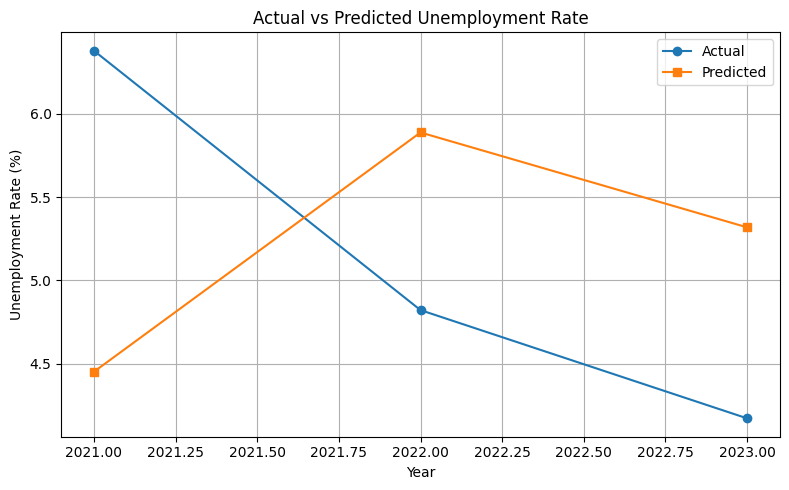

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    results["Year"],
    results["Actual Unemployment Rate"],
    marker="o",
    label="Actual"
)

plt.plot(
    results["Year"],
    results["Predicted Unemployment Rate"],
    marker="s",
    label="Predicted"
)

plt.title("Actual vs Predicted Unemployment Rate")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

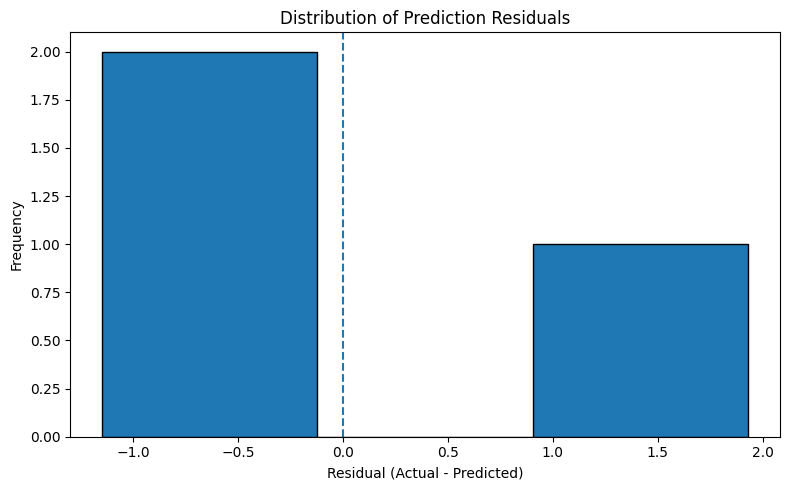

In [27]:
results["Residual"] = (
    results["Actual Unemployment Rate"]
    - results["Predicted Unemployment Rate"]
)

plt.figure(figsize=(8, 5))

plt.hist(
    results["Residual"],
    bins=3,
    edgecolor="black"
)

plt.axvline(0, linestyle="--")

plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

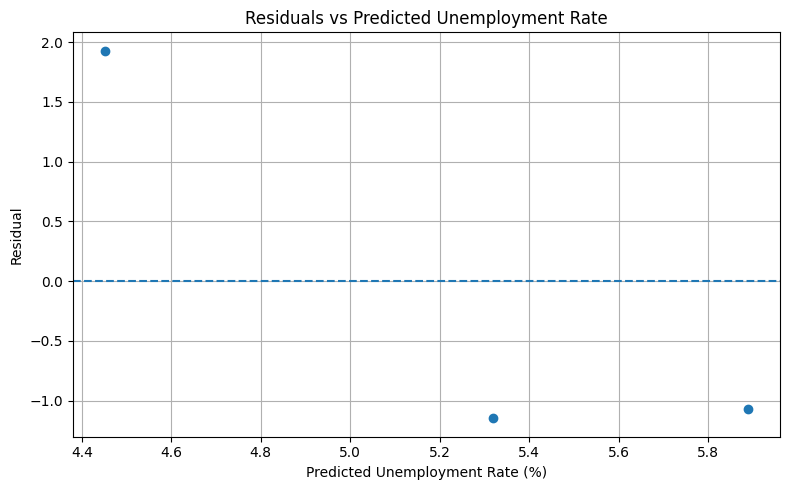

In [28]:
plt.figure(figsize=(8, 5))

plt.scatter(
    results["Predicted Unemployment Rate"],
    results["Residual"]
)

plt.axhline(0, linestyle="--")

plt.title("Residuals vs Predicted Unemployment Rate")
plt.xlabel("Predicted Unemployment Rate (%)")
plt.ylabel("Residual")
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
from tensorflow.keras import regularizers

tf.keras.utils.set_random_seed(42)

simple_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.05)
    ),
    Dropout(0.3),
    Dense(1, activation="linear")
])

simple_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

simple_history = simple_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=200,
    batch_size=4,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=20,
            restore_best_weights=True
        )
    ],
    verbose=0
)

simple_pred = simple_model.predict(X_test_scaled).flatten()

print("Simpler MLP results")
print("Epochs:", len(simple_history.history["loss"]))
print("MAE:", round(mean_absolute_error(y_test, simple_pred), 4))
print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_test, simple_pred)), 4)
)
print("R-squared:", round(r2_score(y_test, simple_pred), 4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
Simpler MLP results
Epochs: 137
MAE: 0.7277
RMSE: 0.8484
R-squared: 0.1615


In [30]:
comparison = pd.DataFrame({
    "Model": ["Original MLP", "Simpler MLP"],
    "MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, simple_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, simple_pred))
    ],
    "R2": [
        r2_score(y_test, y_pred),
        r2_score(y_test, simple_pred)
    ]
})

display(comparison.round(4))

comparison.to_csv(
    "model_comparison.csv",
    index=False
)

print("Saved model_comparison.csv")

,Model,MAE,RMSE,R2
0,Original MLP,1.3808,1.4344,-1.3971
1,Simpler MLP,0.7277,0.8484,0.1615


Saved model_comparison.csv


In [31]:
from google.colab import files
files.download("model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
# Step 1: Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Step 2: Check duplicate years
print("Duplicate years:", df["year"].duplicated().sum())

# Step 3: Check outliers using the IQR method
numeric_columns = df.select_dtypes(include="number").columns.drop("year")

outlier_summary = []

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": count
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

Duplicate rows: 0
Duplicate years: 0


,Feature,Lower Bound,Upper Bound,Potential Outliers
0,unemployment_rate,7.442000e+00,7.756000e+00,5
1,gdp_growth,9.578566e-01,1.210218e+01,1
2,gdp_per_capita,-9.295289e+02,3.626210e+03,0
3,inflation,-6.879297e-01,1.179131e+01,1
4,labor_force_participation,4.459412e+01,6.697313e+01,0
5,population,8.757089e+08,1.656027e+09,0
6,urban_population_percent,2.347538e+01,3.913271e+01,0
7,internet_users_percent,-2.125261e+01,4.262409e+01,4
8,foreign_direct_investment,-2.323764e+10,8.363392e+10,0
9,trade_percent_gdp,2.491329e+01,6.346073e+01,0


In [33]:
# Inspect potential outliers using the IQR method

numeric_columns = df.select_dtypes(include="number").columns.drop("year")

outlier_details = []

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = (df[column] < lower_bound) | (df[column] > upper_bound)

    for _, row in df.loc[mask, ["year", column]].iterrows():
        outlier_details.append({
            "Feature": column,
            "Year": int(row["year"]),
            "Value": row[column],
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound
        })

outlier_details_df = pd.DataFrame(outlier_details)

if outlier_details_df.empty:
    print("No potential outliers found.")
else:
    display(outlier_details_df)

,Feature,Year,Value,Lower Bound,Upper Bound
0,unemployment_rate,2019,6.510000,7.442000,7.756000
1,unemployment_rate,2020,7.859000,7.442000,7.756000
2,unemployment_rate,2021,6.380000,7.442000,7.756000
3,unemployment_rate,2022,4.822000,7.442000,7.756000
4,unemployment_rate,2023,4.172000,7.442000,7.756000
5,gdp_growth,2020,-5.777725,0.957857,12.102182
6,inflation,2010,11.989390,-0.687930,11.791306
7,internet_users_percent,2020,43.405443,-21.252614,42.624089
8,internet_users_percent,2021,49.258099,-21.252614,42.624089
9,internet_users_percent,2022,55.900000,-21.252614,42.624089


In [34]:
# Final data-quality check

print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nInfinite values in each numeric column:")
print(
    np.isinf(df.select_dtypes(include="number"))
    .sum()
)

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate years:", df["year"].duplicated().sum())

print("\nYear range:", df["year"].min(), "-", df["year"].max())

Dataset shape: (24, 17)

Missing values in each column:
year                          0
unemployment_rate             0
gdp_growth                    0
gdp_per_capita                0
inflation                     0
labor_force_participation     0
population                    0
urban_population_percent      0
internet_users_percent        0
foreign_direct_investment     0
trade_percent_gdp             0
life_expectancy               0
female_labor_participation    0
agriculture_value_added       0
industry_value_added          0
services_value_added          0
gross_capital_formation       0
dtype: int64

Infinite values in each numeric column:
year                          0
unemployment_rate             0
gdp_growth                    0
gdp_per_capita                0
inflation                     0
labor_force_participation     0
population                    0
urban_population_percent      0
internet_users_percent        0
foreign_direct_investment     0
trade_percent_gdp         

### Data Quality Assessment and Preprocessing

The dataset contains 24 annual observations and 17 columns, covering the period from 2000 to 2023. The data-quality assessment identified no missing values, infinite values, duplicate rows, or duplicate years. Potential outliers were identified using the Interquartile Range (IQR) method. These observations were retained because statistical outliers are not necessarily data errors, and genuine economic changes should not be removed without justification. The dataset was checked for consistency before proceeding with exploratory data analysis and deep learning model development.

,Feature,Mean MAE Increase
7,foreign_direct_investment,0.407014
11,agriculture_value_added,0.254465
10,female_labor_participation,0.181123
3,labor_force_participation,0.171535
12,industry_value_added,0.111919
13,services_value_added,0.086003
6,internet_users_percent,0.083427
0,gdp_growth,0.028198
4,population,-0.008178
1,gdp_per_capita,-0.041356


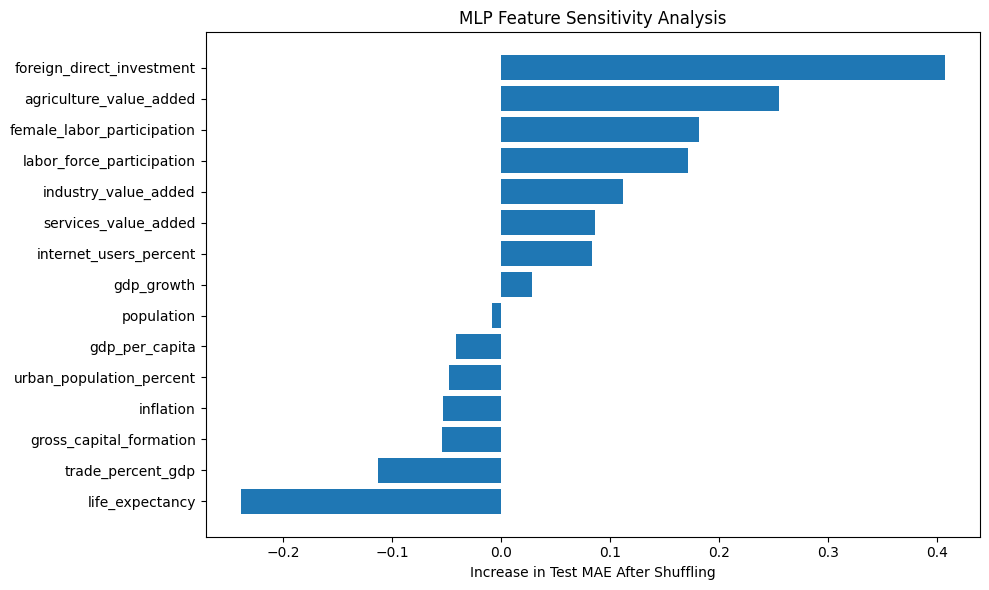

In [35]:
# Feature sensitivity analysis using permutation importance

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def model_predict(features):
    return simple_model.predict(features, verbose=0).flatten()

# Calculate baseline MAE on the test set
baseline_predictions = model_predict(X_test_scaled)
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

importance_results = []

# Shuffle one feature at a time and observe the change in MAE
rng = np.random.default_rng(42)

for i, feature in enumerate(feature_columns):
    changes = []

    for _ in range(20):
        shuffled = X_test_scaled.copy()
        shuffled[:, i] = rng.permutation(shuffled[:, i])

        shuffled_predictions = model_predict(shuffled)
        shuffled_mae = mean_absolute_error(y_test, shuffled_predictions)

        changes.append(shuffled_mae - baseline_mae)

    importance_results.append({
        "Feature": feature,
        "Mean MAE Increase": np.mean(changes)
    })

importance_df = pd.DataFrame(importance_results)
importance_df = importance_df.sort_values(
    "Mean MAE Increase", ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Mean MAE Increase"][::-1]
)
plt.xlabel("Increase in Test MAE After Shuffling")
plt.title("MLP Feature Sensitivity Analysis")
plt.tight_layout()
plt.show()

In [36]:
# Descriptive statistics for the dataset

display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
year,24.0,2.011500e+03,7.071000e+00,2.000000e+03,2.005750e+03,2.011500e+03,2.017250e+03,2.023000e+03
unemployment_rate,24.0,7.272000e+00,9.250000e-01,4.172000e+00,7.560000e+00,7.618000e+00,7.638000e+00,7.859000e+00
gdp_growth,24.0,6.164000e+00,3.094000e+00,-5.778000e+00,5.137000e+00,7.310000e+00,7.923000e+00,9.690000e+00
gdp_per_capita,24.0,1.352983e+03,6.325030e+02,4.427500e+02,7.788730e+02,1.431083e+03,1.917808e+03,2.434448e+03
inflation,24.0,6.139000e+00,2.531000e+00,3.328000e+00,3.992000e+00,5.390000e+00,7.112000e+00,1.198900e+01
labor_force_participation,24.0,5.544400e+01,2.977000e+00,5.154700e+01,5.298600e+01,5.441400e+01,5.858100e+01,6.007900e+01
population,24.0,1.262709e+09,1.184499e+08,1.057923e+09,1.168328e+09,1.269950e+09,1.363408e+09,1.438070e+09
urban_population_percent,24.0,3.133900e+01,2.339000e+00,2.764700e+01,2.934700e+01,3.143200e+01,3.326100e+01,3.506800e+01
internet_users_percent,24.0,1.614700e+01,1.818700e+01,5.280000e-01,2.701000e+00,1.058500e+01,1.867000e+01,6.025200e+01
foreign_direct_investment,24.0,2.972690e+10,1.752012e+10,3.584217e+09,1.683919e+10,3.136484e+10,4.355708e+10,6.436236e+10


In [37]:
# Display complete descriptive statistics without truncation

stats = df.describe().T.round(3)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 200)

display(stats)

,count,mean,std,min,25%,50%,75%,max
year,24.0,2.011500e+03,7.071000e+00,2.000000e+03,2.005750e+03,2.011500e+03,2.017250e+03,2.023000e+03
unemployment_rate,24.0,7.272000e+00,9.250000e-01,4.172000e+00,7.560000e+00,7.618000e+00,7.638000e+00,7.859000e+00
gdp_growth,24.0,6.164000e+00,3.094000e+00,-5.778000e+00,5.137000e+00,7.310000e+00,7.923000e+00,9.690000e+00
gdp_per_capita,24.0,1.352983e+03,6.325030e+02,4.427500e+02,7.788730e+02,1.431083e+03,1.917808e+03,2.434448e+03
inflation,24.0,6.139000e+00,2.531000e+00,3.328000e+00,3.992000e+00,5.390000e+00,7.112000e+00,1.198900e+01
labor_force_participation,24.0,5.544400e+01,2.977000e+00,5.154700e+01,5.298600e+01,5.441400e+01,5.858100e+01,6.007900e+01
population,24.0,1.262709e+09,1.184499e+08,1.057923e+09,1.168328e+09,1.269950e+09,1.363408e+09,1.438070e+09
urban_population_percent,24.0,3.133900e+01,2.339000e+00,2.764700e+01,2.934700e+01,3.143200e+01,3.326100e+01,3.506800e+01
internet_users_percent,24.0,1.614700e+01,1.818700e+01,5.280000e-01,2.701000e+00,1.058500e+01,1.867000e+01,6.025200e+01
foreign_direct_investment,24.0,2.972690e+10,1.752012e+10,3.584217e+09,1.683919e+10,3.136484e+10,4.355708e+10,6.436236e+10


In [38]:
print("Training set:", len(X_train), "observations")
print("Validation set:", len(X_val), "observations")
print("Test set:", len(X_test), "observations")

print("\nTraining years:", df.loc[train_mask, "year"].min(),
      "to", df.loc[train_mask, "year"].max())

print("Validation years:", df.loc[val_mask, "year"].min(),
      "to", df.loc[val_mask, "year"].max())

print("Test years:", df.loc[test_mask, "year"].min(),
      "to", df.loc[test_mask, "year"].max())

Training set: 18 observations
Validation set: 3 observations
Test set: 3 observations

Training years: 2000 to 2017
Validation years: 2018 to 2020
Test years: 2021 to 2023


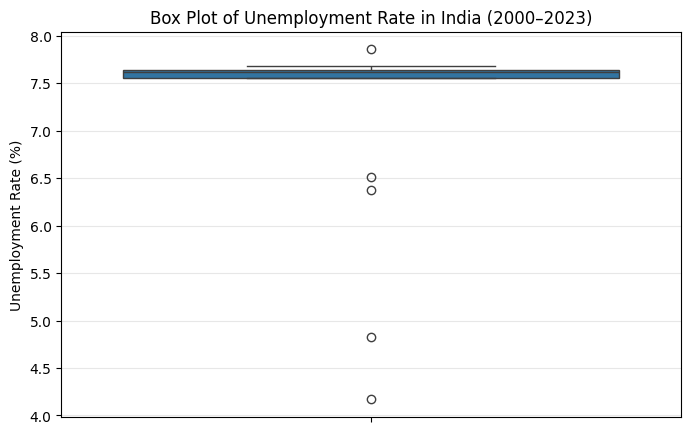

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(y=df["unemployment_rate"])

plt.title("Box Plot of Unemployment Rate in India (2000–2023)")
plt.ylabel("Unemployment Rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.show()

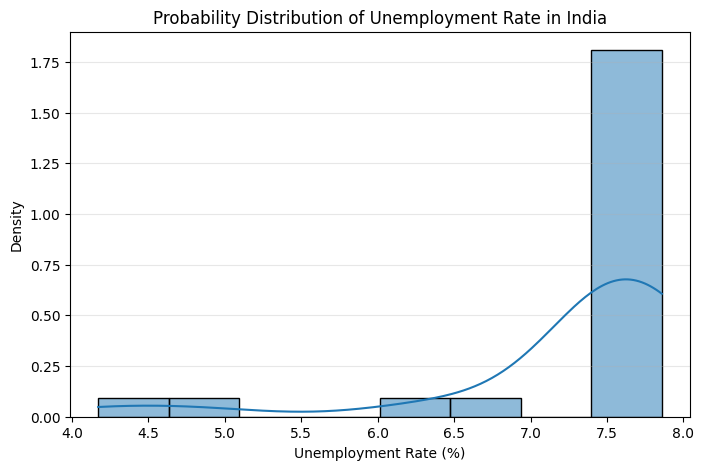

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="unemployment_rate",
    bins=8,
    kde=True,
    stat="density"
)

plt.title("Probability Distribution of Unemployment Rate in India")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Density")
plt.grid(axis="y", alpha=0.3)
plt.show()

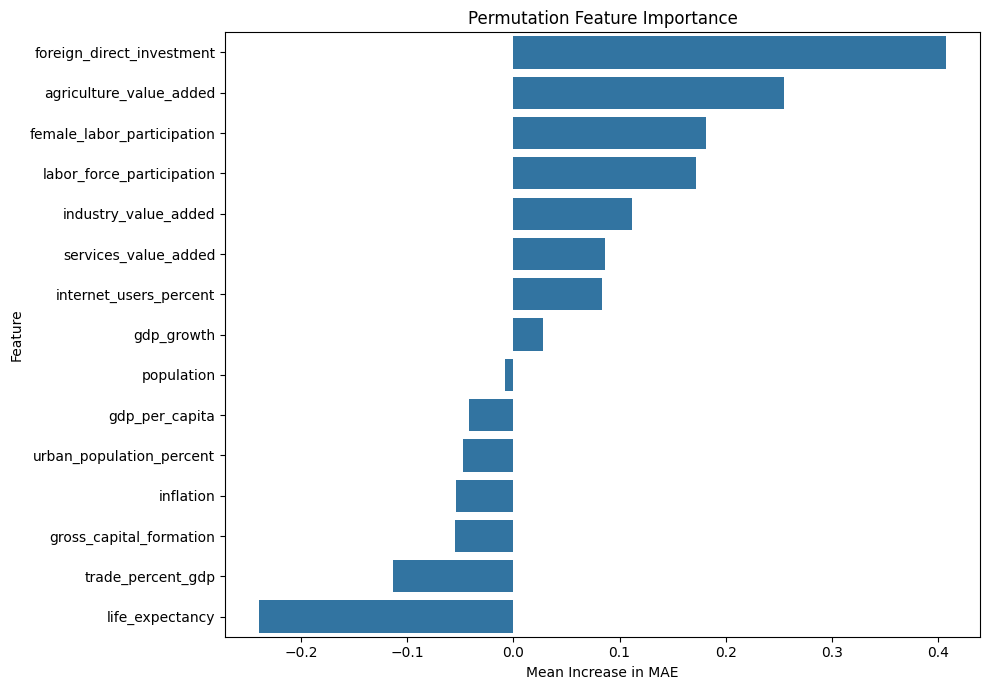

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort using the correct, existing DataFrame 'importance_df'
sorted_importance_df = importance_df.sort_values(
    "Mean MAE Increase", ascending=False
)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=sorted_importance_df,
    x="Mean MAE Increase",
    y="Feature"
)
plt.title("Permutation Feature Importance")
plt.xlabel("Mean Increase in MAE")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()